In [24]:
%pip install torchinfo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
from torchinfo import summary
from torch.utils.data import DataLoader, TensorDataset

In [26]:
df_train = pd.read_csv("C:\\Users\\acer\\Downloads\\DL\\trainset.csv")
df_test = pd.read_csv("C:\\Users\\acer\\Downloads\\DL\\testset.csv")

In [27]:
train_prices = df_train['Close'].values.reshape(-1, 1)
test_prices = df_test['Close'].values.reshape(-1, 1)

In [28]:
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train_prices)
scaled_test = scaler.transform(test_prices)

In [29]:
def create_sequences(data, seq_length):
    x = []
    y = []
    for i in range(len(data) - seq_length):
        x.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(x), np.array(y)

seq_length = 60
x_train, y_train = create_sequences(scaled_train, seq_length)
x_test, y_test = create_sequences(scaled_test, seq_length)

In [30]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((1199, 60, 1), (1199, 1), (65, 60, 1), (65, 1))

In [31]:
x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [32]:
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [33]:
class RNNModel(nn.Module):
  def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
    super(RNNModel, self).__init__()
    self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first = True)
    self.fc = nn.Linear(hidden_size, output_size)

  def forward(self,x):
    out, _ = self.rnn(x)
    out = self.fc(out[:, -1, :])
    return out

model = RNNModel()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [34]:
model = RNNModel()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [35]:
summary(model, input_size=(64, 60, 1))


Layer (type:depth-idx)                   Output Shape              Param #
RNNModel                                 [64, 1]                   --
├─RNN: 1-1                               [64, 60, 64]              12,608
├─Linear: 1-2                            [64, 1]                   65
Total params: 12,673
Trainable params: 12,673
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 48.42
Input size (MB): 0.02
Forward/backward pass size (MB): 1.97
Params size (MB): 0.05
Estimated Total Size (MB): 2.03

In [36]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [37]:
epochs = 20
model.train()
train_losses = []
for epoch in range(epochs):
  epoch_loss = 0
  for x_batch, y_batch in train_loader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device)
    optimizer.zero_grad()
    outputs = model(x_batch)
    loss = criterion(outputs, y_batch)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()
  train_losses.append(epoch_loss / len(train_loader))
  print(f"Epoch [{epoch+1}/{epochs}], Loss:{train_losses[-1]:.4f}")

Epoch [1/20], Loss:0.0675
Epoch [2/20], Loss:0.0140
Epoch [3/20], Loss:0.0022
Epoch [4/20], Loss:0.0007
Epoch [5/20], Loss:0.0006
Epoch [6/20], Loss:0.0005
Epoch [7/20], Loss:0.0005
Epoch [8/20], Loss:0.0005
Epoch [9/20], Loss:0.0004
Epoch [10/20], Loss:0.0004
Epoch [11/20], Loss:0.0004
Epoch [12/20], Loss:0.0004
Epoch [13/20], Loss:0.0004
Epoch [14/20], Loss:0.0004
Epoch [15/20], Loss:0.0004
Epoch [16/20], Loss:0.0004
Epoch [17/20], Loss:0.0003
Epoch [18/20], Loss:0.0003
Epoch [19/20], Loss:0.0003
Epoch [20/20], Loss:0.0003


Name : Sujin M L
Register Number : 212225040435


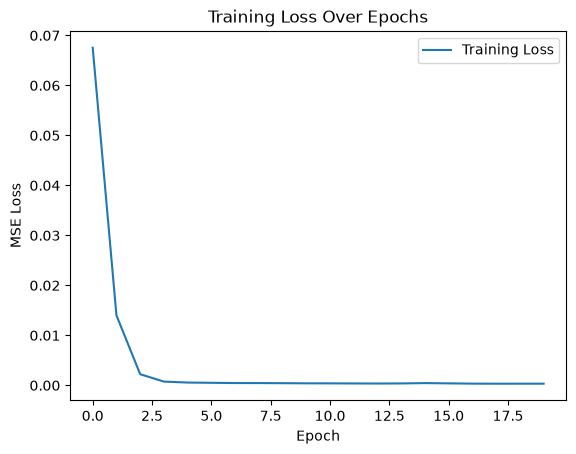

In [42]:
print("Name : Sujin M L")
print("Register Number : 212225040435")
plt.plot(train_losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss Over Epochs')
plt.legend()
plt.show()

Name: Sujin M L
Register Number : 212225040435 


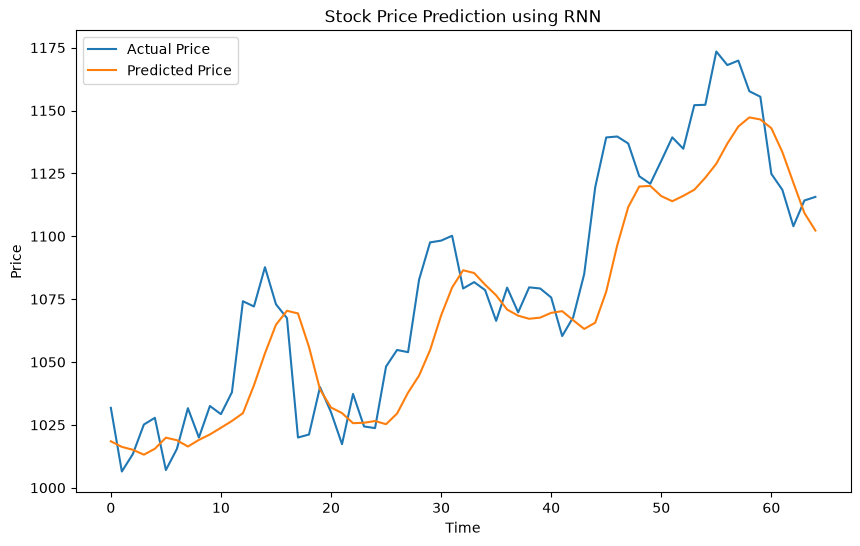

Predicted Price: [1102.2655]
Actual Price: [1115.65]


In [43]:
model.eval()
with torch.no_grad():
    predicted = model(x_test_tensor.to(device)).cpu().numpy()
    actual = y_test_tensor.cpu().numpy()
    

predicted_prices = scaler.inverse_transform(predicted)
actual_prices = scaler.inverse_transform(actual)

print("Name: Sujin M L")
print("Register Number : 212225040435 ")
plt.figure(figsize=(10, 6))
plt.plot(actual_prices, label='Actual Price')
plt.plot(predicted_prices, label='Predicted Price')
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Stock Price Prediction using RNN')
plt.legend()
plt.show()
print(f'Predicted Price: {predicted_prices[-1]}')
print(f'Actual Price: {actual_prices[-1]}')
